# E4: prefix-search cost vs prefix length (track_name, all rows)

Question: how does the cost of `prefix_search` depend on prefix length, and which index is best for F2 (search-as-you-type)?
Data: `E4_prefix_track_name` rows from `results/timings.csv`, one machine, one code version. 500 prefixes per length, 5 replicates.

Every index answers a prefix query as the range `[prefix, prefix + U+10FFFF]` (`indexes/base.py`). So the ordered indexes find the start with a search and walk forward, while the unordered ones (unsorted list, hash table, `ref_dict`) have to look at every key.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df = pd.read_csv(Path("..") / "results" / "timings.csv")
e4 = df[df["experiment"] == "E4_prefix_track_name"]

# Control the comparison: one machine, one code version.
machine = "ike-mba"
version = e4[e4["machine_id"] == machine]["code_version"].iloc[-1]
e4 = e4[(e4["machine_id"] == machine) & (e4["code_version"] == version)].copy()

e4["prefix_length"] = e4["operation_param"].astype(int)
e4["us_per_op"] = e4["total_ns"] / e4["n_ops"] / 1_000
e4["avg_matches"] = e4["notes"].str.extract(r"avg_matches=([\d.]+)").astype(float)
for c in ["comparisons", "nodes_visited"]:
    e4[c + "_per_op"] = e4[c] / e4["n_ops"]

print(machine, version, len(e4), "rows, n_keys =", e4["n_keys"].iloc[0])
e4.groupby("prefix_length")["avg_matches"].first().rename("avg rows returned per prefix")

ike-mba 7c43369 175 rows, n_keys = 113999


prefix_length
1    5315.5
2     956.0
3     256.9
4     163.9
5      51.4
Name: avg rows returned per prefix, dtype: float64

## Median and IQR across the 5 replicates (µs per prefix query)

In [2]:
summary = (
    e4.groupby(["index_type", "prefix_length"])["us_per_op"]
    .quantile([0.25, 0.5, 0.75]).unstack()
    .rename(columns={0.25: "q25", 0.5: "median", 0.75: "q75"})
)
summary["median"].unstack("prefix_length").round(1)

prefix_length,1,2,3,4,5
index_type,,,,,
avl_tree,1183.8,194.6,54.8,32.3,13.7
bplus_tree,4249.7,4206.8,4192.3,3918.2,3654.2
hash_table,10741.1,9980.4,9927.1,9915.5,11658.6
ref_bisect,93.2,20.2,8.2,5.8,3.2
ref_dict,2577.1,2213.4,2180.1,2189.3,2113.3
sorted_list,472.5,87.7,25.5,15.6,7.1
unsorted_list,2773.5,2654.2,2636.3,2673.1,2740.2


## Cost vs prefix length

Line = median over replicates, band = IQR. Log y-axis: the indexes are orders of magnitude apart.

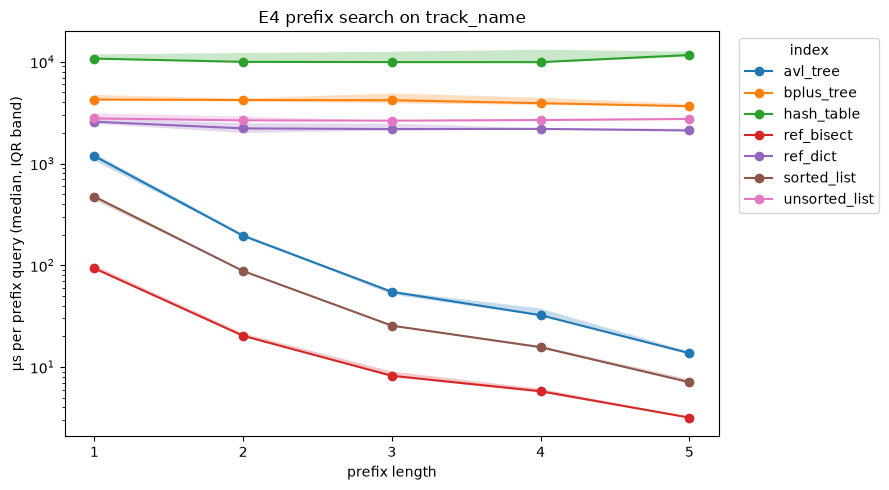

In [3]:
fig, ax = plt.subplots(figsize=(9, 5))
for index_type in summary.index.get_level_values(0).unique():
    s = summary.loc[index_type]
    ax.plot(s.index, s["median"], marker="o", label=index_type)
    ax.fill_between(s.index, s["q25"], s["q75"], alpha=0.25)
ax.set(yscale="log", xlabel="prefix length", ylabel="µs per prefix query (median, IQR band)",
       xticks=sorted(e4["prefix_length"].unique()), title="E4 prefix search on track_name")
ax.legend(title="index", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()

## Separating search cost from output cost

A prefix query costs (find the start) + (walk and copy every match). Short prefixes match thousands of rows, so even a perfect index pays for the output.
Dividing by the average number of rows returned shows how much each index pays *per result*.

In [4]:
per_match = summary["median"].unstack("prefix_length") / e4.groupby("prefix_length")["avg_matches"].first()
per_match.round(3)

prefix_length,1,2,3,4,5
index_type,,,,,
avl_tree,0.223,0.204,0.213,0.197,0.266
bplus_tree,0.799,4.400,16.319,23.906,71.093
hash_table,2.021,10.440,38.642,60.497,226.821
ref_bisect,0.018,0.021,0.032,0.035,0.062
ref_dict,0.485,2.315,8.486,13.357,41.114
sorted_list,0.089,0.092,0.099,0.095,0.138
unsorted_list,0.522,2.776,10.262,16.309,53.311


## Counters per query

Comparisons and nodes visited are deterministic, so one replicate is enough.

In [5]:
counted = e4[e4["comparisons"].notna() & (e4["rep"] == 0)]
counted.pivot_table(index="index_type", columns="prefix_length",
                    values=["comparisons_per_op", "nodes_visited_per_op"]).round(0)

comparisons_per_op                                          \
prefix_length                  1         2         3         4         5   
index_type                                                                 
avl_tree                  3348.0     608.0     173.0     114.0      42.0   
bplus_tree               72396.0   72396.0   72396.0   72396.0   72396.0   
hash_table               72396.0   72396.0   72396.0   72396.0   72396.0   
sorted_list               3349.0     609.0     174.0     114.0      43.0   
unsorted_list           113999.0  113999.0  113999.0  113999.0  113999.0   

              nodes_visited_per_op                                      
prefix_length                    1        2        3        4        5  
index_type                                                              
avl_tree                    3348.0    608.0    173.0    114.0     42.0  
bplus_tree                  3497.0   3497.0   3497.0   3497.0   3497.0  
hash_table                 97288.0  97288.0  97288.0  97288.0  97288.0  
sorted_list                    0.0      0.0      0.0      0.0      0.0  
unsorted_list                  0.0      0.0      0.0      0.0      0.0

## Best index at each prefix length (crossovers)

In [6]:
med = summary["median"].unstack("prefix_length")
main = med.drop(index=["ref_dict", "ref_bisect"])
pd.DataFrame({"best main index": main.idxmin(), "µs": main.min().round(1),
              "runner-up": main.apply(lambda c: c.nsmallest(2).index[-1]),
              "ref_bisect µs": med.loc["ref_bisect"].round(1)})

,best main index,µs,runner-up,ref_bisect µs
prefix_length,,,,
1,sorted_list,472.5,avl_tree,93.2
2,sorted_list,87.7,avl_tree,20.2
3,sorted_list,25.5,avl_tree,8.2
4,sorted_list,15.6,avl_tree,5.8
5,sorted_list,7.1,avl_tree,3.2


## Observations (draft: reword in your own words before submitting)

- **Ordered vs unordered.** The unsorted list, hash table and `ref_dict` cost the same at every prefix length (about 2,700, 10,000 and 2,200 µs), because they examine every key (113,999, 72,396 and 72,396 comparisons per query). That is expected: hashing scatters keys, so nothing tells you where the strings starting with `lov` are. The hash table is about 4× *slower* than the plain unsorted scan, because it also visits 97,288 buckets per query.
- **Prefix length.** For the ordered indexes, cost drops sharply as the prefix grows (sorted list: 473 µs at length 1 → 7.1 µs at length 5) because the number of matches drops (5,316 → 51 rows on average). Per row returned, the sorted list costs about 0.09–0.15 µs at every length and the AVL tree about 0.2–0.27 µs, so their cost is output-bound: O(log n + k), where k is the number of matches. Comparisons per query ≈ k + log2(n) (3,349 at length 1, 43 at length 5).
- **Sorted list vs `ref_bisect`.** Same algorithm, same answers. `ref_bisect` is 2–5× faster, which is the Python-vs-C constant factor. The big-O is identical.
- **B+ tree is not behaving like an ordered index.** It makes 72,396 comparisons and visits 3,497 nodes per query *at every prefix length*. That is every distinct key and every leaf, so its prefix/range search walks the whole leaf chain instead of starting at `lo` and stopping after `hi`. Result: about 3,700–4,200 µs, slower than the unsorted list. This looks like a performance bug in `indexes/bplus_tree.py` `range_search` (part 3 / E3). Rerun E4 after it's fixed.
- **Recommendation for F2 (current code).** The sorted list is the best main index at every prefix length (crossover: none). The AVL tree is second at about 2× the cost. Search-as-you-type mostly sees short prefixes (1–3 characters), where output size dominates. Re-check the B+ tree after its fix.